In [100]:
%pip install astropy astroquery reproject requests matplotlib numpy


Note: you may need to restart the kernel to use updated packages.


In [101]:
import os
import certifi
os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()
import re
import requests
import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS
from astropy.nddata import Cutout2D
from astropy.coordinates import SkyCoord
from astropy import units as u
from astropy.visualization import (ImageNormalize,PercentileInterval,AsinhStretch)

from astroquery.ipac.irsa import Irsa
from reproject import reproject_interp



## Defining the EDF-N Target
I use a position near the Euclid Deep Field North (EDF-N), centred at at RA=269.733°, Dec=66.018°

In [102]:

ra = 269.733
dec = 66.018
coord = SkyCoord(ra, dec, unit="deg", frame="icrs")
search_radius = 10 * u.arcmin

image_table = Irsa.query_sia(pos=(coord, search_radius),collection="euclid_DpdMerBksMosaic",facility="Euclid")
print("Products returned:", len(image_table))
print(image_table["instrument_name", "energy_bandpassname", "dataproduct_subtype"])

Products returned: 48
instrument_name energy_bandpassname dataproduct_subtype
--------------- ------------------- -------------------
            VIS                 VIS           auxiliary
            VIS                 VIS           auxiliary
            VIS                 VIS               noise
            VIS                 VIS           auxiliary
            VIS                 VIS             science
            VIS                 VIS           auxiliary
           NISP                   H           auxiliary
           NISP                   H           auxiliary
           NISP                   H             science
           NISP                   H               noise
            ...                 ...                 ...
           NISP                   J             science
           NISP                   J           auxiliary
           NISP                   J           auxiliary
           NISP                   J               noise
           NISP           

In [103]:
science_images = image_table[image_table["dataproduct_subtype"] == "science"]
print(science_images["instrument_name","energy_bandpassname","access_url"])

instrument_name ...
--------------- ...
            VIS ...
           NISP ...
           NISP ...
           NISP ...
            VIS ...
           NISP ...
           NISP ...
           NISP ...


In [104]:
vis_url=str(science_images[science_images["energy_bandpassname"]=='VIS']["access_url"][0])
print(vis_url)

https://irsa.ipac.caltech.edu/ibe/data/euclid/q1/MER/102159192/VIS/EUC_MER_BGSUB-MOSAIC-VIS_TILE102159192-DC9889_20241025T010247.818212Z_00.00.fits


## Testing a small VIS cutout
Before processing a full sqaure degree I verify that the FITS image and visualization pipeline work on a 1 arcmin cutout

application/fits
Downloaded bytes: 1451520


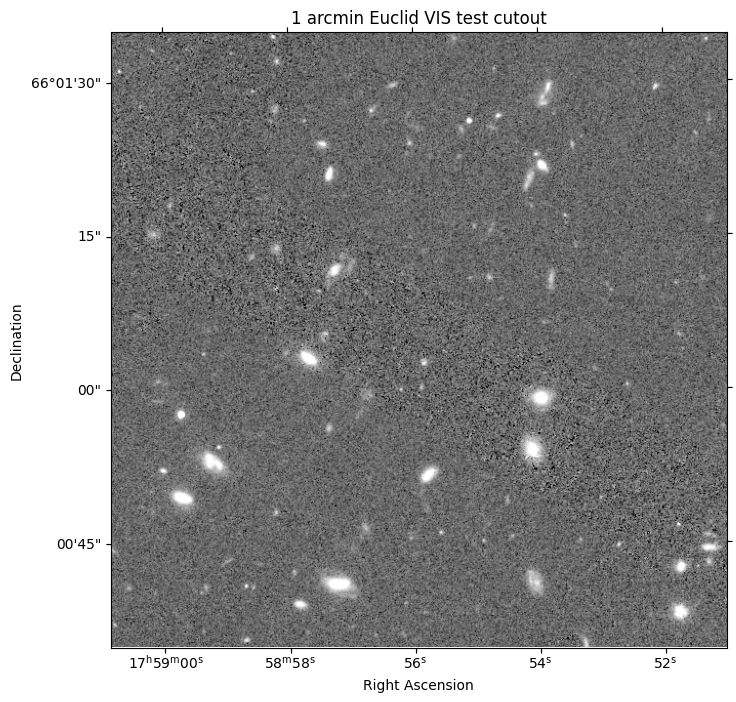

In [105]:
import io
import certifi
import requests
# Request only a 1 arcmin cutout instead of opening the full VIS FITS file
cutout_url = (vis_url+ f"?center={ra},{dec}deg"+ "&size=1arcmin"+ "&gzip=false")

response = requests.get(cutout_url,timeout=120,verify=certifi.where())
response.raise_for_status()
print(response.headers.get("Content-Type"))
print("Downloaded bytes:", len(response.content))

with fits.open(io.BytesIO(response.content)) as hdul:
    cutout_data = hdul[0].data
    cutout_wcs = WCS(hdul[0].header)

norm = ImageNormalize( cutout_data,interval=PercentileInterval(99.5),stretch=AsinhStretch())
plt.figure(figsize=(8, 8))
ax = plt.subplot(projection=cutout_wcs)
ax.imshow(cutout_data,origin="lower",cmap="gray",norm=norm)
ax.set_xlabel("Right Ascension")
ax.set_ylabel("Declination")
ax.set_title("1 arcmin Euclid VIS test cutout")
plt.show()

In [106]:
ra_center = 269.733
dec_center = 66.018
dec_height = 1.0
ra_width = 1 / np.cos(np.deg2rad(dec_center))
ra_min = ra_center - ra_width/2
ra_max = ra_center + ra_width/2
dec_min = dec_center - dec_height/2
dec_max = dec_center + dec_height/2
print("RA:", ra_min, ra_max)
print("Dec:", dec_min, dec_max)


RA: 268.5028352509585 270.9631647490415
Dec: 65.518 66.518


Correct RA width for convergence of longitude lines at high declination

##  Identify Euclid tiles covering the target region

In [107]:
ra_points = np.linspace(ra_min, ra_max, 5)
dec_points = np.linspace(dec_min, dec_max, 5)
all_rows = []
for ra_i in ra_points:
    for dec_i in dec_points:
        c = SkyCoord(ra_i, dec_i, unit='deg', frame='icrs')
        table = Irsa.query_sia(pos=(c, 10*u.arcsec), collection='euclid_DpdMerBksMosaic', facility='Euclid')
        for row in table:
            if(row["dataproduct_subtype"]=="science" and row['energy_bandpassname']=='VIS'):
                all_rows.append(row)

In [108]:
vis_urls=[]
for row in all_rows:
    url=str(row["access_url"])
    if url not in vis_urls:
        vis_urls.append(url)
print(f"Number of VIS tiles: {len(vis_urls)}")


Number of VIS tiles: 9


In [109]:
tiles = []
for row in all_rows:
    url = str(row["access_url"])

    if not any(tile["url"] == url for tile in tiles):
        tiles.append({"ra": float(row["s_ra"]),"dec": float(row["s_dec"]),"url": url})
print("Tiles found:", len(tiles))

Tiles found: 9


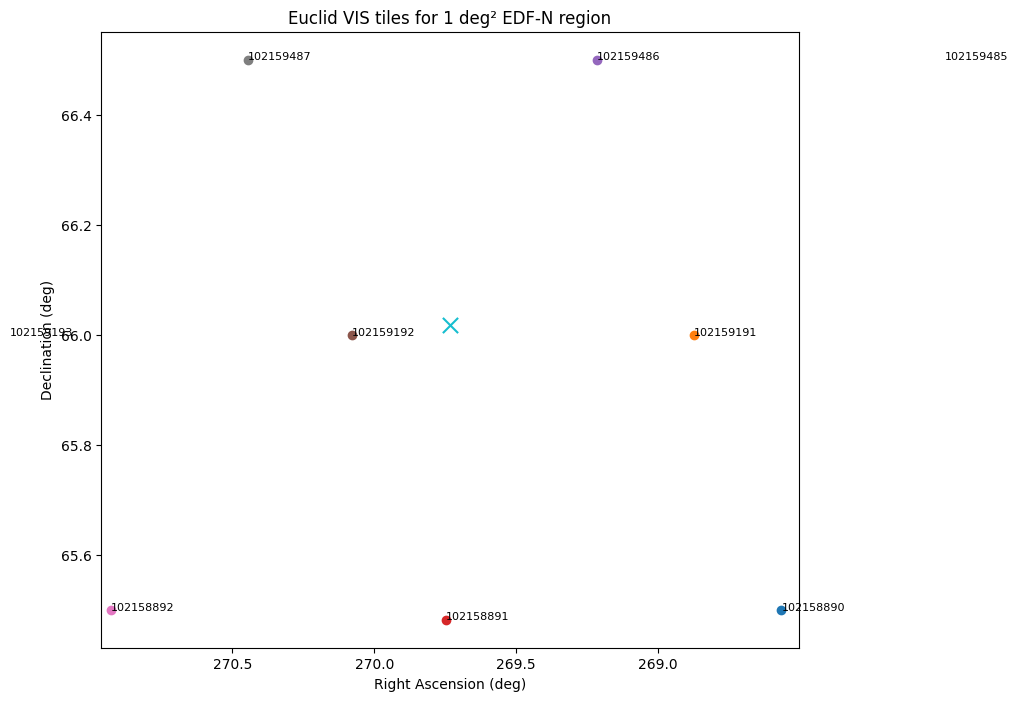

In [110]:
plt.figure(figsize=(9, 8))
for tile in tiles:
    match = re.search(r"/MER/(\d+)/", tile["url"])
    if match:
        tile_id = match.group(1)
    else:
        tile_id = "unknown"
    plt.scatter(tile["ra"], tile["dec"])
    plt.text(tile["ra"],tile["dec"],tile_id,fontsize=8)
plt.scatter(ra_center,dec_center,marker="x",s=120)
plt.xlim(ra_max, ra_min)
plt.xlabel("Right Ascension (deg)")
plt.ylabel("Declination (deg)")
plt.title("Euclid VIS tiles for 1 deg² EDF-N region")
plt.show()

## Defining a common mosaic grid
All input tiles are reprojected onto an 1800×1800 TAN projection 

In [111]:
npix = 1800
pixel_scale = 2.0 / 3600.0
mosaic_wcs = WCS(naxis=2)
mosaic_wcs.wcs.crpix = [npix / 2,npix / 2]
mosaic_wcs.wcs.crval = [ra_center,dec_center]
mosaic_wcs.wcs.cdelt = [-pixel_scale,pixel_scale]
mosaic_wcs.wcs.ctype = ["RA---TAN", "DEC--TAN"]
shape_out = (npix, npix)

In [112]:
import os

os.makedirs("euclid_tiles", exist_ok=True)

for i, tile in enumerate(tiles):

    filename = f"euclid_tiles/tile_{i+1}.fits"


    if os.path.exists(filename):
        print("Already exists:", filename)
        continue

    print("Downloading tile", i + 1, "of", len(tiles))

    cutout_url = (
        tile["url"]
        + f"?center={ra_center},{dec_center}deg"
        + "&size=1deg"
        + "&gzip=false"
    )

    try:
        response = requests.get(
            cutout_url,
            timeout=600
        )

        response.raise_for_status()

        with open(filename, "wb") as f:
            f.write(response.content)

        print("saved:", filename)

    except Exception as e:
        print("failed:", e)

Already exists: euclid_tiles/tile_1.fits
Already exists: euclid_tiles/tile_2.fits
Already exists: euclid_tiles/tile_3.fits
Already exists: euclid_tiles/tile_4.fits
Already exists: euclid_tiles/tile_5.fits
Already exists: euclid_tiles/tile_6.fits
Already exists: euclid_tiles/tile_7.fits
Already exists: euclid_tiles/tile_8.fits
Already exists: euclid_tiles/tile_9.fits


In [113]:
images = []

for i in range(1, 10):
    filename = f"euclid_tiles/tile_{i}.fits"

    hdul = fits.open(filename)

    data = hdul[0].data
    header = hdul[0].header

    images.append(
        (data, WCS(header))
    )

    print("loaded:", filename, data.shape)

loaded: euclid_tiles/tile_1.fits (8794, 10494)
loaded: euclid_tiles/tile_2.fits (19200, 15023)
loaded: euclid_tiles/tile_3.fits (10605, 2050)
loaded: euclid_tiles/tile_4.fits (9005, 19200)
loaded: euclid_tiles/tile_5.fits (10279, 19200)
loaded: euclid_tiles/tile_6.fits (19200, 19200)
loaded: euclid_tiles/tile_7.fits (8786, 10086)
loaded: euclid_tiles/tile_8.fits (10307, 17180)
loaded: euclid_tiles/tile_9.fits (19200, 4896)


In [114]:
npix = 1800
pixel_scale = 2.0 / 3600.0   

mosaic_wcs = WCS(naxis=2)

mosaic_wcs.wcs.crpix = [
    npix / 2,
    npix / 2
]

mosaic_wcs.wcs.crval = [
    ra_center,
    dec_center
]

mosaic_wcs.wcs.cdelt = [
    -pixel_scale,
    pixel_scale
]

mosaic_wcs.wcs.ctype = [
    "RA---TAN",
    "DEC--TAN"
]

shape_out = (npix, npix)

##  Reproject and combine the VIS tiles
Each tile has its own WCS. I reproject every tile onto the common
output grid and use the reprojection footprint as a weight when
averaging overlapping pixels.

In [115]:
mosaic_sum = np.zeros(shape_out)
mosaic_weight = np.zeros(shape_out)

for i, (data, image_wcs) in enumerate(images):

    print("Reprojecting", i + 1, "of", len(images))

    reproj, footprint = reproject_interp(
        (data, image_wcs),
        mosaic_wcs,
        shape_out=shape_out
    )

    good = np.isfinite(reproj) & (footprint > 0)

    mosaic_sum[good] += reproj[good]
    mosaic_weight[good] += footprint[good]
mosaic = np.full(shape_out, np.nan)

good = mosaic_weight > 0

mosaic[good] = (
    mosaic_sum[good]
    / mosaic_weight[good]
)


Reprojecting 1 of 9
Reprojecting 2 of 9
Reprojecting 3 of 9
Reprojecting 4 of 9
Reprojecting 5 of 9
Reprojecting 6 of 9
Reprojecting 7 of 9
Reprojecting 8 of 9
Reprojecting 9 of 9


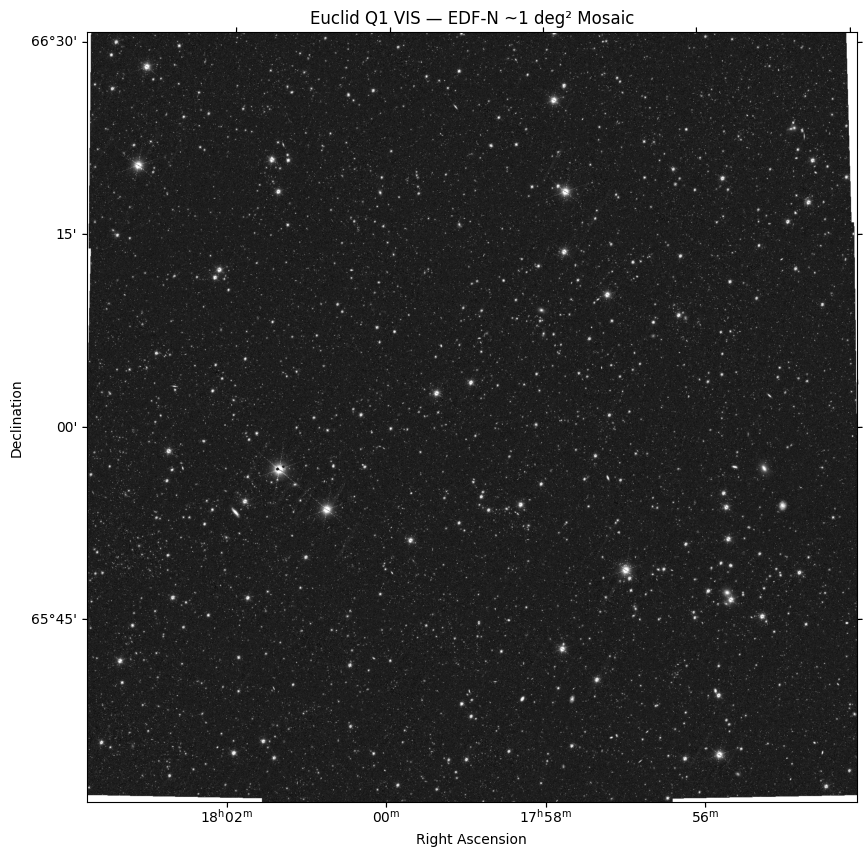

In [116]:
norm = ImageNormalize(
    mosaic,
    interval=PercentileInterval(99.5),
    stretch=AsinhStretch()
)

plt.figure(figsize=(10, 10))

ax = plt.subplot(
    projection=mosaic_wcs
)

ax.imshow(
    mosaic,
    origin="lower",
    cmap="gray",
    norm=norm
)

ax.set_xlabel("Right Ascension")
ax.set_ylabel("Declination")

ax.set_title(
    "Euclid Q1 VIS — EDF-N ~1 deg² Mosaic"
)

plt.show()
vis_mosaic = mosaic.copy()

In [117]:
def get_band_mosaic(band, folder):
    """
    Download cached Euclid MER tiles for one band and
    reproject/combine them onto the common mosaic grid.
    """
    os.makedirs(folder, exist_ok=True)

   
    for i, tile in enumerate(tiles):

        filename = f"{folder}/tile_{i+1}.fits"

        if os.path.exists(filename):
            print("already exists:", filename)
            continue

        c = SkyCoord(tile["ra"], tile["dec"], unit="deg")

        table = Irsa.query_sia(
            pos=(c, 10*u.arcsec),
            collection="euclid_DpdMerBksMosaic",
            facility="Euclid"
        )

        science = table[
            table["dataproduct_subtype"] == "science"
        ]

        band_rows = science[
            science["energy_bandpassname"] == band
        ]

        if len(band_rows) == 0:
            print("no", band, "for tile", i+1)
            continue

        url = str(band_rows["access_url"][0])

        cutout_url = (
            url
            + f"?center={ra_center},{dec_center}deg"
            + "&size=1deg"
            + "&gzip=false"
        )

        try:
            print("Downloading", band, "tile", i+1, "of 9")

            response = requests.get(
                cutout_url,
                timeout=600
            )

            response.raise_for_status()

            with open(filename, "wb") as f:
                f.write(response.content)

            print("saved:", filename)

        except Exception as e:
            print("failed:", e)

  
    mosaic_sum = np.zeros(shape_out)
    mosaic_weight = np.zeros(shape_out)

    for i in range(1, 10):

        filename = f"{folder}/tile_{i}.fits"

        if not os.path.exists(filename):
            continue

        print("Reprojecting", filename)

        with fits.open(filename) as hdul:
            data = hdul[0].data
            image_wcs = WCS(hdul[0].header)

            reproj, footprint = reproject_interp(
                (data, image_wcs),
                mosaic_wcs,
                shape_out=shape_out
            )

        good = np.isfinite(reproj) & (footprint > 0)

        mosaic_sum[good] += reproj[good]
        mosaic_weight[good] += footprint[good]

    result = np.full(shape_out, np.nan)

    good = mosaic_weight > 0
    result[good] = mosaic_sum[good] / mosaic_weight[good]

    return result
y_mosaic = get_band_mosaic("Y", "euclid_tiles_Y")
h_mosaic = get_band_mosaic("H", "euclid_tiles_H")

Reprojecting euclid_tiles_H/tile_2.fits
Reprojecting euclid_tiles_H/tile_3.fits
Reprojecting euclid_tiles_H/tile_4.fits
Reprojecting euclid_tiles_H/tile_5.fits
Reprojecting euclid_tiles_H/tile_6.fits
Reprojecting euclid_tiles_H/tile_7.fits
Reprojecting euclid_tiles_H/tile_8.fits
Reprojecting euclid_tiles_H/tile_9.fits


In [118]:
print(vis_mosaic.shape)
print(y_mosaic.shape)
print(h_mosaic.shape)

(1800, 1800)
(1800, 1800)
(1800, 1800)


In [119]:
def stretch_image(data, low_p=0.5, high_p=99.85, strength=15):

    finite = np.isfinite(data)

    low, high = np.nanpercentile(data[finite],[low_p, high_p])

    scaled = (data - low) / (high - low)

    scaled = np.clip(scaled, 0, 1)

    scaled = np.arcsinh(strength*scaled) / np.arcsinh(strength)

    scaled[~finite] = 0

    return scaled

In [120]:
VIS = stretch_image(vis_mosaic, strength=18)
Y = stretch_image(y_mosaic, strength=14)
H = stretch_image(h_mosaic, strength=12)
rgb = (np.dstack([np.clip(H*1.15,0,1) , np.clip(Y*1.05,0,1), np.clip(VIS*1.20, 0, 1)]))**0.90


##  Create the H/Y/VIS false-color composite

Channel mapping:
- Red = NISP-H
- Green = NISP-Y
- Blue = VIS

I apply percentile normalization and an asinh stretch to make faint
sources visible while limiting saturation of bright sources. The channel multipliers and gamma are visualization choices 

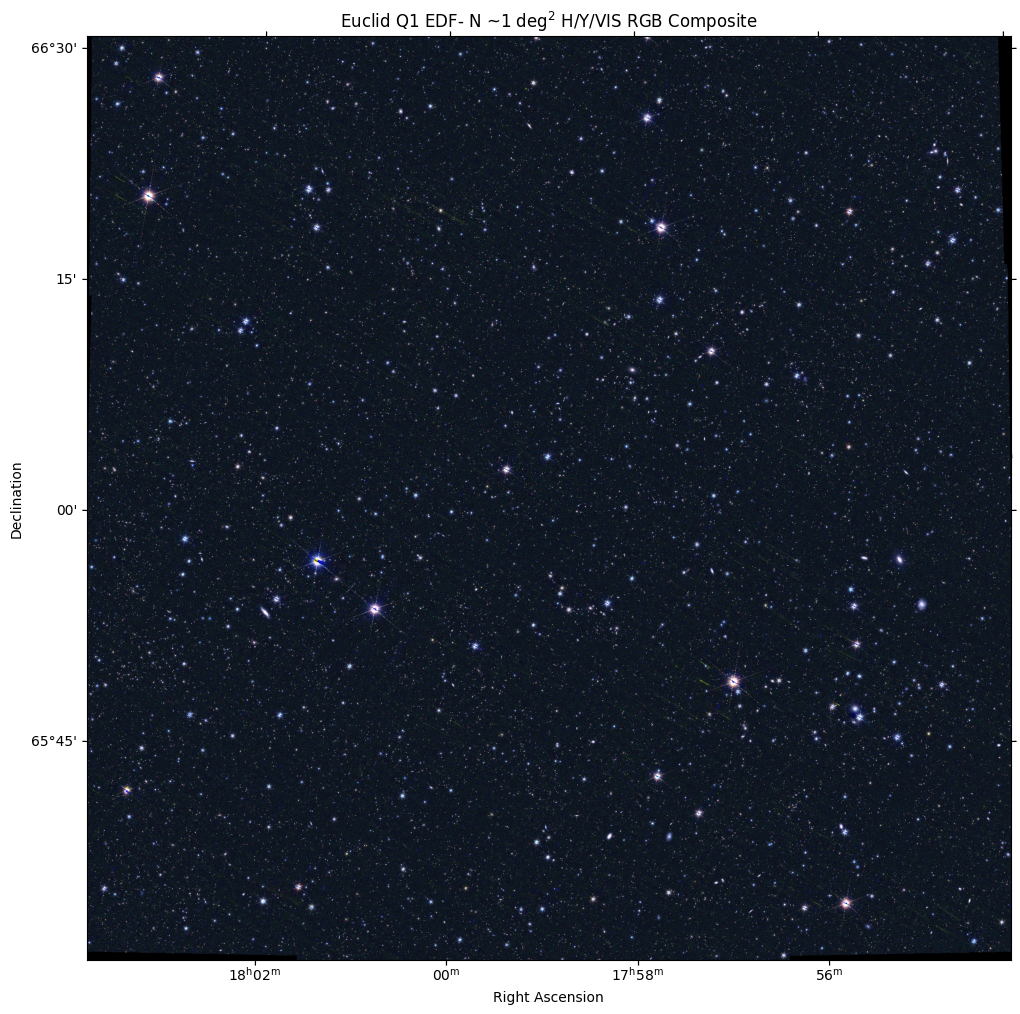

In [121]:
fig=plt.figure(figsize=(12, 12))

ax = plt.subplot(projection=mosaic_wcs)

ax.imshow(rgb,origin="lower")

ax.set_xlabel("Right Ascension")
ax.set_ylabel("Declination")

ax.set_title("Euclid Q1 EDF- N ~1 deg$^2$ H/Y/VIS RGB Composite")
fig.savefig("Euclid_EDFN_1deg2_RGB_final.png",dpi=300,bbox_inches="tight")

plt.show()